# Final 2 – Analyse, modellen en deployment: hoeveel Citi Bikes vertrekken er per zone per uur?

| | |
|---|---|
| **Auteur(s)** | Kobe Vandenberk |
| **Wat** | Alles na de cleaning, in één verhaal: wat de data vertelt (EDA), twee getoetste hypotheses, de keuze van het model op 2024, het definitieve model op alle data, de foutenanalyse en de deployment. Bij elke poging: **waarom** we het probeerden, **wat** het opleverde, en **waarom we er wel of niet mee verder gingen**. |
| **Input** | `data/model_table.parquet` (uit `01_cleaning`), `data/2024/*` (studie op 2024), `models/` (opgeslagen zoekresultaten) |
| **Output** | `deploy/citi_bike_demand/model.pkl` (via `train.py`) |
| **GenAI** | Code en tekst opgesteld met hulp van Claude; keuzes en resultaten nagekeken door Kobe. |

## Leeswijzer
| Deel | Vraag | Data |
|---|---|---|
| **A. EDA** | Wanneer en waar fietst New York, en wat bepaalt dat? | 2024 en alle jaren |
| **B. Hypotheses** | Is er een echt, statistisch onderbouwd patroon om te voorspellen? | 2024 |
| **C. Modelselectie** | Welke techniek werkt het best? | 2024 |
| **D. Definitief model** | Wordt de beste techniek beter met 13 jaar data? | alle jaren |
| **E. Foutenanalyse** | Waar vergist het definitieve model zich, en waarom? | alle jaren |
| **F. Deployment** | Hoe komt het model bij de gebruiker? | |
| **G. Conclusie** | Wat werkte, wat niet, en waarom? | |

**Waarom eerst op 2024 en daarna op alle data?** Op één jaar (263.000 zone-uren) duurt een model trainen seconden, op alle jaren (2,8 miljoen zone-uren) minuten. We vergeleken de technieken daarom grondig op 2024 en trainden alleen de winnaar op alle data.

### Zoektochten opnieuw uitvoeren of niet?
Het zoeken naar hyperparameters (randomized search, PyCaret) duurt samen enkele uren. Met `RUN_SEARCHES = False` (standaard) gebruikt dit notebook de gevonden instellingen en de opgeslagen zoekresultaten uit `models/` (gemaakt door de werknotebooks `05b`–`05e` en `08` in de map erboven), en traint en meet het alle modellen zelf opnieuw. Met `RUN_SEARCHES = True` wordt ook elke zoektocht opnieuw uitgevoerd.

In [1]:
RUN_SEARCHES = False

## 0. Imports en data

In [2]:
%matplotlib inline
import json
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from scipy.stats import loguniform, randint, uniform
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import PoissonRegressor
from sklearn.model_selection import GridSearchCV, GroupKFold, RandomizedSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, SplineTransformer, StandardScaler

KOBE = Path.cwd().parent
sys.path.insert(0, str(KOBE))
import citibike as cb

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
GREEN, ORANGE, INK, BLUE = "#2f6f4f", "#c47f00", "#17201b", "#3b6fb6"

# Studie op 2024
t24 = cb.load_model_table(cb.DATA_2024 / "model_table.parquet")
sh24 = pd.read_parquet(cb.DATA_2024 / "station_hour.parquet")
st24 = cb.clean_stations(pd.read_parquet(cb.DATA_2024 / "stations.parquet"))
w24 = pd.read_parquet(cb.DATA_2024 / "weather_2024.parquet")
# Alle data
table = cb.load_model_table()
print(f"2024: {len(t24):,} zone-uren | alle data: {len(table):,} zone-uren "
      f"({table['time'].min():%Y-%m} t/m {table['time'].max():%Y-%m}), {table['trips'].sum():,} vertrekken")


def hgb(features=cb.FEATURES, **params):
    """HistGradientBoosting met Poisson-verlies en de zone als categorie (de gekozen techniek)."""
    return HistGradientBoostingRegressor(loss="poisson", categorical_features=[features.index("zone")],
                                         random_state=cb.SEED, **params)


def test_frame(tab, y_test, pred):
    return tab.loc[y_test.index, ["zone", "time", "trips"]].assign(pred=pred)


def paired_bootstrap(pa, pb, n=2000, seed=cb.SEED):
    """MAE(b) - MAE(a) op de testset, hertrokken per dag (opeenvolgende uren hangen samen)."""
    err = pd.DataFrame({"day": pa["time"].dt.normalize(), "a": (pa["trips"] - pa["pred"]).abs(),
                        "b": (pb["trips"] - pb["pred"]).abs()})
    per_day = err.groupby("day")[["a", "b"]].agg(["sum", "count"])
    sa, sb, cnt = per_day[("a", "sum")].to_numpy(), per_day[("b", "sum")].to_numpy(), per_day[("a", "count")].to_numpy()
    idx = np.random.default_rng(seed).integers(0, len(per_day), size=(n, len(per_day)))
    diff = sb[idx].sum(1) / cnt[idx].sum(1) - sa[idx].sum(1) / cnt[idx].sum(1)
    return {"MAE-winst": round(float(diff.mean()), 2), "95%-BI": np.round(np.percentile(diff, [2.5, 97.5]), 2).tolist(),
            "P(beter)": round(float((diff > 0).mean()), 3)}

2024: 263,520 zone-uren | alle data: 2,818,992 zone-uren (2013-06 t/m 2026-09), 328,688,926 vertrekken


---
# Deel A – EDA: wat bepaalt de vraag?
Het doel van de EDA is niet een verzameling grafieken, maar de vraag: **welke informatie heeft een model nodig om de vraag te voorspellen?** Elke vaststelling hieronder eindigt in een gevolg voor het model.

## A1. Dertien jaar groei

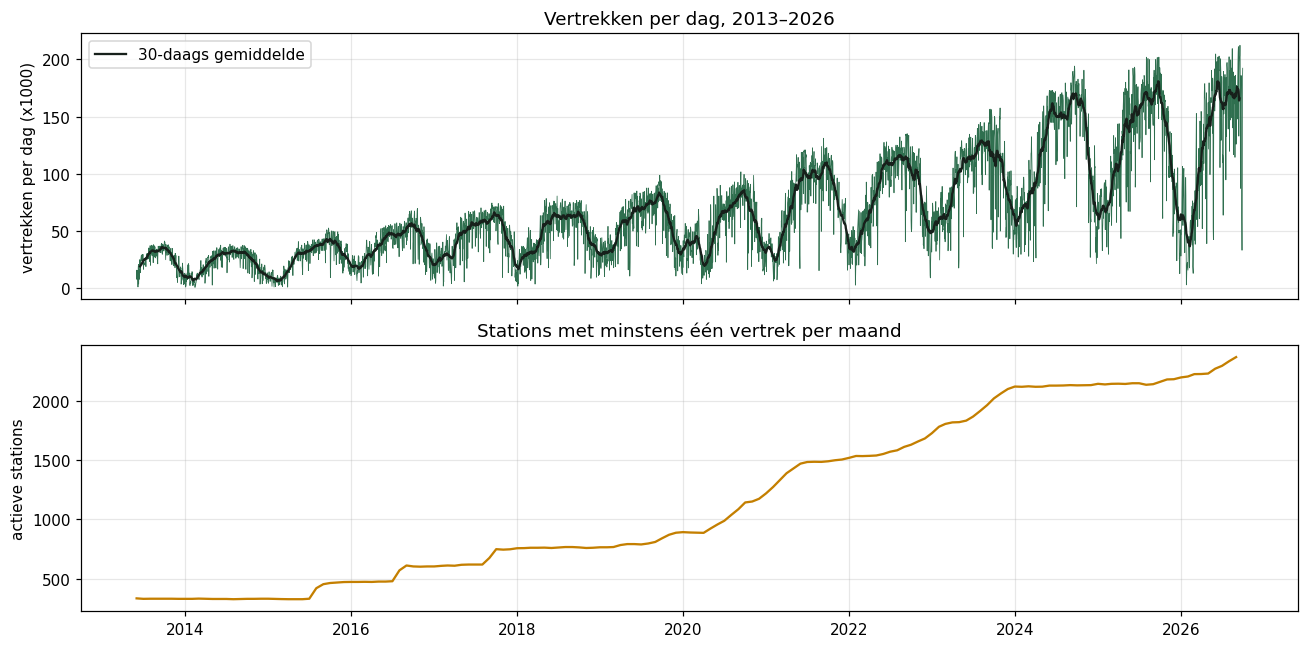

time,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
trips,5613171.0,8081216.0,9937954.0,13844352.0,16362735.0,17544527.0,20551820.0,19561911.0,27128930.0,29837939.0,35088143.0,44270097.0,45745677.0,35120454.0
% member,83.9,90.2,86.8,88.8,89.1,89.0,86.0,77.0,73.2,77.9,81.2,80.7,82.6,81.9
% e-bike,0.0,0.0,0.0,0.0,0.0,0.0,0.0,14.1,31.8,39.3,50.1,66.1,70.4,72.6


In [3]:
daily_all = table.groupby(table["time"].dt.normalize())["trips"].sum()
active_month = table.groupby([table["time"].dt.to_period("M"), "zone"])["active_stations"].first().groupby(level=0).sum()
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(daily_all.index, daily_all / 1000, color=GREEN, lw=.5)
axes[0].plot(daily_all.rolling(30, center=True).mean() / 1000, color=INK, lw=1.5, label="30-daags gemiddelde")
axes[0].set(ylabel="vertrekken per dag (x1000)", title="Vertrekken per dag, 2013–2026"); axes[0].legend()
axes[1].plot(active_month.index.to_timestamp(), active_month.values, color=ORANGE)
axes[1].set(ylabel="actieve stations", title="Stations met minstens één vertrek per maand")
plt.tight_layout()
plt.show()
yearly = table.groupby(table["time"].dt.year)[["trips", "members", "electric"]].sum()
(yearly.assign(**{"% member": yearly["members"] / yearly["trips"] * 100, "% e-bike": yearly["electric"] / yearly["trips"] * 100})
       [["trips", "% member", "% e-bike"]].round(1).T)

**Vaststelling:**
- de vraag groeit van ± 35.000 vertrekken per dag in de zomer van 2013 naar ± 170.000 in 2025–2026, altijd met hetzelfde **seizoenspatroon**;
- het netwerk groeit in **sprongen**: 330 stations (2013), ± 750 (2018), ± 1.500 (2021), ± 2.400 (2026). Elke sprong is een uitbreiding naar nieuwe buurten;
- **corona** (voorjaar 2020): een korte dip, daarna de snelste groei ooit, met meer **casual** riders (14% in 2019 → 27% in 2021) en de opkomst van **e-bikes** (0% → 73%).

**Gevolg voor het model:** een model dat alleen kalender en weer kent, begrijpt de groei niet. Het krijgt daarom het **jaar** en het **aantal actieve stations** in de zone als kenmerken (deel D).

## A2. Seizoen en temperatuur (2024)

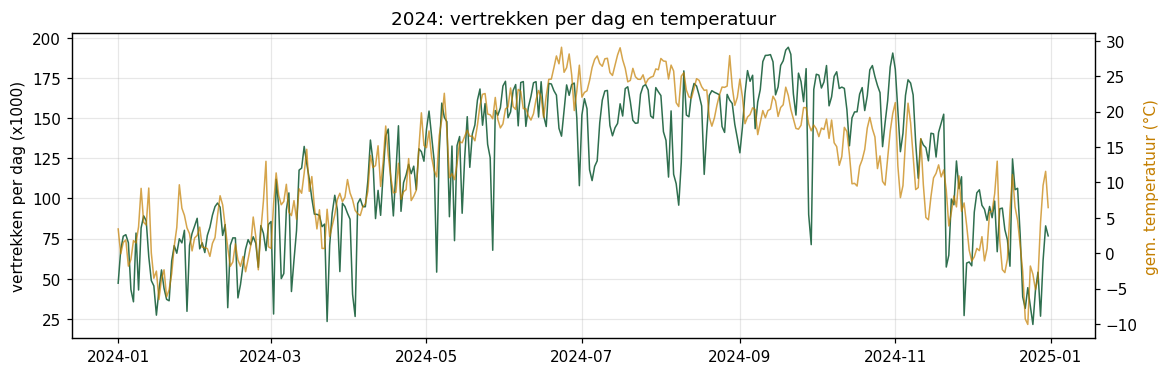

Spearman dagtotaal ~ temperatuur: 0.77


,trips,temperature_c,precipitation_mm
time,,,
2024-12-25,21562,-3.0,0.0
2024-03-23,23396,6.2,63.2
2024-04-03,26526,6.1,25.0
2024-12-28,26708,4.4,5.5
2024-11-28,27089,7.1,17.9


In [4]:
city24 = (t24.groupby("time")[["trips", "members"]].sum().reset_index()
          .merge(w24, on="time", how="left"))
day24 = city24.set_index("time").resample("D").agg({"trips": "sum", "temperature_c": "mean", "precipitation_mm": "sum"})
fig, ax = plt.subplots(figsize=(12, 3.6))
ax.plot(day24.index, day24["trips"] / 1000, color=GREEN, lw=1)
ax.set(ylabel="vertrekken per dag (x1000)", title="2024: vertrekken per dag en temperatuur")
ax2 = ax.twinx(); ax2.plot(day24.index, day24["temperature_c"], color=ORANGE, lw=1, alpha=.7)
ax2.set_ylabel("gem. temperatuur (°C)", color=ORANGE); ax2.grid(False)
plt.show()
print("Spearman dagtotaal ~ temperatuur:", round(day24["trips"].corr(day24["temperature_c"], method="spearman"), 2))
day24.nsmallest(5, "trips").round(1)

**Vaststelling:** het dagtotaal volgt de temperatuur (Spearman ρ = 0,77), en de diepste dalen buiten de kerstperiode zijn regendagen (23 maart: 63 mm). De piek ligt in september–oktober, niet in juli: na de zomervakantie fietsen forenzen en studenten weer.

**Gevolg:** temperatuur, neerslag, maand en feestdagen moeten in het model.

## A3. Het dagritme (2024)

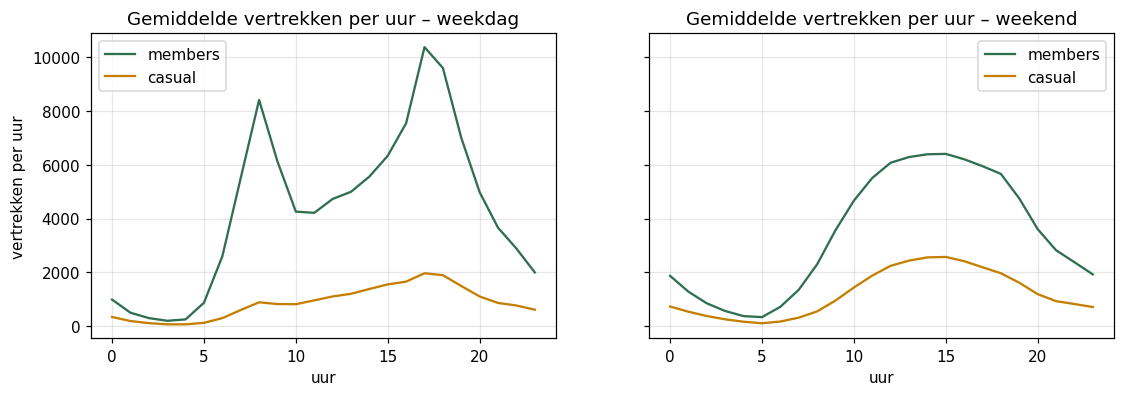

In [5]:
city24["hour"] = city24["time"].dt.hour
city24["daytype"] = np.where(city24["time"].dt.dayofweek >= 5, "weekend", "weekdag")
city24["casual"] = city24["trips"] - city24["members"]
profile = city24.groupby(["daytype", "hour"])[["members", "casual"]].mean()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, daytype in zip(axes, ["weekdag", "weekend"]):
    profile.loc[daytype].plot(ax=ax, color=[GREEN, ORANGE])
    ax.set(title=f"Gemiddelde vertrekken per uur – {daytype}", xlabel="uur", ylabel="vertrekken per uur")
plt.show()

**Vaststelling:** op **weekdagen** twee pieken bij members (8u en, hoger, 17u): woon-werkverkeer. In het **weekend** één brede bult van 10u tot 19u: vrijetijdsfietsen.

**Gevolg:** het uur alleen volstaat niet; het model moet **uur × weekdag/weekend** combineren. (In deel B toetsen we dit.)

## A4. Waar? Stationsprofielen (unsupervised learning)
De zones (KMeans op locatie, zie `01_cleaning` §10) zeggen *waar*. Maar gedragen alle buurten zich hetzelfde? We clusteren de stations een tweede keer, nu op hun **gedrag**: per station het aandeel van zijn vertrekken per uur, apart voor weekdagen en weekend (48 getallen die samen 1 zijn). Zo vergelijken we de *vorm* van het dagpatroon, los van hoe druk een station is. Stations met minstens 2.000 vertrekken in 2024.

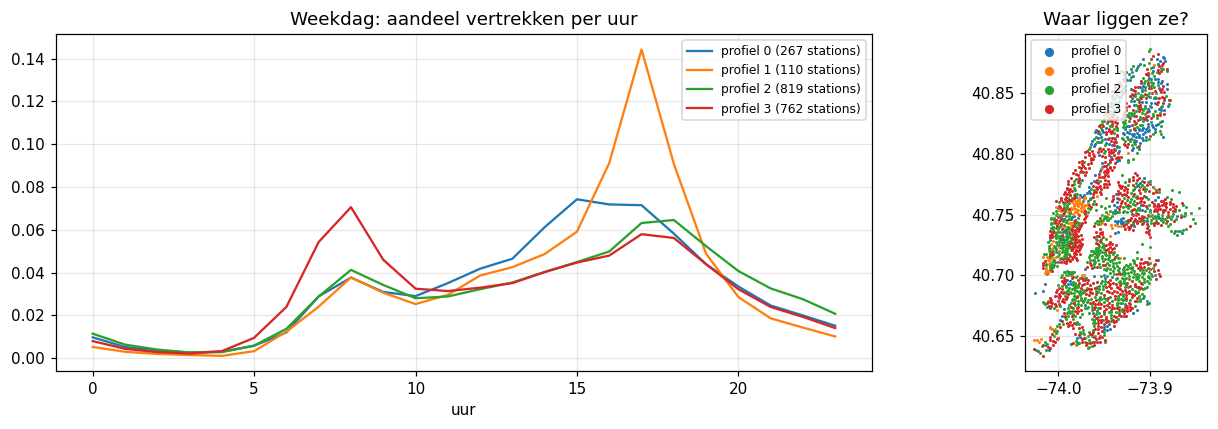

In [6]:
public24 = st24[st24["keep"]]
sh = sh24[sh24["start_station_id"].isin(set(public24.loc[public24["trips"] >= 2000, "start_station_id"]))]
sh = sh.assign(slot=sh["time"].dt.hour + 24 * (sh["time"].dt.dayofweek >= 5))
prof = sh.pivot_table(index="start_station_id", columns="slot", values="trips", aggfunc="sum", fill_value=0)
prof = prof.div(prof.sum(axis=1), axis=0)
behaviour = KMeans(4, n_init=10, random_state=cb.SEED).fit(prof)
prof_clusters = pd.Series(behaviour.labels_, index=prof.index, name="profiel")
fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [1.4, 1]})
for c in range(4):
    axes[0].plot(range(24), behaviour.cluster_centers_[c][:24], label=f"profiel {c} ({int((prof_clusters == c).sum())} stations)")
axes[0].set(title="Weekdag: aandeel vertrekken per uur", xlabel="uur"); axes[0].legend(fontsize=8)
geo = public24.set_index("start_station_id").join(prof_clusters, how="inner")
for c in range(4):
    part = geo[geo["profiel"] == c]
    axes[1].scatter(part["lng"], part["lat"], s=4, lw=0, label=f"profiel {c}")
axes[1].set(title="Waar liggen ze?"); axes[1].set_aspect(1 / np.cos(np.radians(40.73))); axes[1].legend(markerscale=3, fontsize=8)
plt.tight_layout()
plt.show()

**Vaststelling:** zonder dat we het model iets over buurten vertellen, vindt KMeans vier soorten stations:
- **woonbuurten** (± 760 stations): de grootste piek om **8u**, mensen vertrekken van thuis (Upper East/West Side, Brooklyn, Queens);
- **kantoorwijken** (± 110 stations, Midtown en het Financial District): een enorme piek om **17u** en bijna geen ochtendpiek;
- een profiel met een piek rond **15u** (Harlem, de Bronx: het einde van de schooldag);
- een **gemengd** profiel met veel avondritten (Lower Manhattan, Williamsburg).

**Gevolg:** het dagritme hangt af van de plaats. Het model heeft de interactie **zone × uur × daltype** nodig. Een lineair model krijgt die alleen als we ze expliciet maken; bomen vinden ze zelf (deel C). Het verklaart ook waarom herverdeling nodig is: 's ochtends lopen woonbuurten leeg en kantoorwijken vol, 's avonds omgekeerd.

## A5. De target

Gemiddeld 117 vertrekken per zone-uur, variantie 23,576, maximum 2,075; 4.2% van de zone-uren zonder vertrek


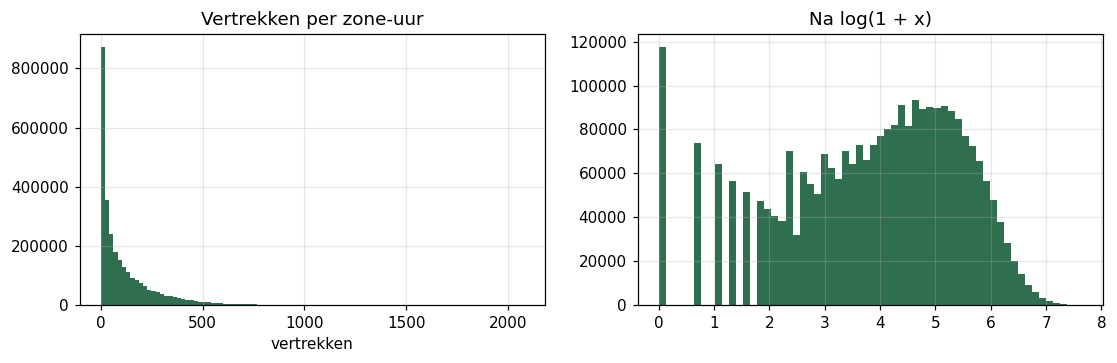

In [7]:
print(f"Gemiddeld {table['trips'].mean():.0f} vertrekken per zone-uur, variantie {table['trips'].var():,.0f}, "
      f"maximum {table['trips'].max():,}; {(table['trips'] == 0).mean():.1%} van de zone-uren zonder vertrek")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
axes[0].hist(table["trips"], bins=100, color=GREEN); axes[0].set(title="Vertrekken per zone-uur", xlabel="vertrekken")
axes[1].hist(np.log1p(table["trips"]), bins=60, color=GREEN); axes[1].set(title="Na log(1 + x)")
plt.show()

**Vaststelling:** een **telling**, rechtsscheef, met een variantie die veel groter is dan het gemiddelde (**overdispersie**: de verwachting verschilt sterk per zone en uur).

**Gevolg:** we gebruiken modellen met een **Poisson-verliesfunctie** (voorspellingen altijd > 0, effecten vermenigvuldigend: "regen haalt er 30% af" in plaats van "regen haalt er 5 af") en meten naast de MAE ook de Poisson-deviance.

---
# Deel B – Testbare hypotheses (2024)
Vóór we modellen bouwen: is er een patroon dat **statistisch** standhoudt en **groot genoeg** is om te voorspellen? Twee hypotheses, vooraf vastgelegd, α = 0,05.

## B1. Regen verlaagt de vraag
- H₀: neerslag verandert het aantal vertrekken niet. H₁: in natte uren vertrekken er minder fietsen (eenzijdig).

**Opzet:** regen valt niet willekeurig (vaker in bepaalde maanden of uren). Vergelijk je zomaar alle natte met alle droge uren, dan meet je deels "winter vs. zomer". We vergelijken daarom alleen uren die verder gelijk zijn (**stratificeren**): zelfde uur, daltype en maand. Nat = ≥ 0,5 mm/u, droog = 0 mm.

In [8]:
c = city24.copy()
c["month"] = c["time"].dt.month
c["wet"] = np.select([c["precipitation_mm"] == 0, c["precipitation_mm"] >= 0.5], ["droog", "nat"], "tussen")
strata = c[c["wet"] != "tussen"].groupby(["hour", "daytype", "month", "wet"])["trips"].mean().unstack("wet").dropna()
strata = strata[(strata > 0).all(axis=1)]
log_ratio = np.log(strata["nat"] / strata["droog"])
wilcoxon = stats.wilcoxon(log_ratio, alternative="less")
print(f"{len(log_ratio)} strata; in {(log_ratio < 0).mean():.0%} minder vertrekken bij regen; mediaan nat/droog = {np.exp(log_ratio.median()):.2f}; "
      f"Wilcoxon W = {wilcoxon.statistic:.0f}, p = {wilcoxon.pvalue:.1e}")

# Effectgrootte binnen dezelfde dag: Poisson met een effect per dag en per uur x daltype (volle-rangcodering)
c["day"] = c["time"].dt.strftime("%m-%d")
c["hour_weekday"] = np.where(c["daytype"] == "weekdag", c["hour"], 0)
c["hour_weekend"] = np.where(c["daytype"] == "weekend", c["hour"], 0)
FIXED = "C(hour_weekday) + C(hour_weekend) + C(day)"
d = c[c["wet"] != "tussen"].assign(nat=lambda x: (x["wet"] == "nat").astype(int))
glm_h1 = smf.glm(f"trips ~ {FIXED} + nat", data=d, family=sm.families.Poisson()).fit(
    cov_type="cluster", cov_kwds={"groups": pd.factorize(d["day"])[0]})
lo, hi = glm_h1.conf_int().loc["nat"]
print(f"Binnen dezelfde dag: {np.exp(glm_h1.params['nat']) - 1:+.1%} vertrekken in een nat uur "
      f"(95%-BI {np.exp(lo) - 1:+.1%} tot {np.exp(hi) - 1:+.1%}), eenzijdige p = {stats.norm.cdf(glm_h1.tvalues['nat']):.1e}")

328 strata; in 95% minder vertrekken bij regen; mediaan nat/droog = 0.53; Wilcoxon W = 451, p = 4.8e-54


Binnen dezelfde dag: -26.9% vertrekken in een nat uur (95%-BI -32.3% tot -21.0%), eenzijdige p = 9.2e-16


**Resultaat:** H₀ verworpen. In 95% van de 328 strata is het rustiger bij regen (mediaan: 53% van de droge vraag). Binnen dezelfde dag kost een nat uur **27% van de vertrekken** (95%-BI −32% tot −21%). Het verschil tussen de twee getallen is zelf informatief: de eerste vergelijking bevat ook het effect van "het is een regendag" (wie 's ochtends regen ziet, laat de fiets de hele dag staan), de tweede alleen het effect van dit ene natte uur.

## B2. Het dagritme verschilt tussen weekdag en weekend
- H₀: de verdeling van de vertrekken over de 24 uren is gelijk. H₁: ze verschilt.

**Opzet:** chi-kwadraattoets op de kruistabel daltype × uur. Met 44 miljoen ritten is elke p-waarde ± 0, dus we kijken vooral naar de **effectgrootte** (Cramér's V), en toetsen daarnaast strenger met de **dag** als eenheid (aandeel van de vertrekken in de ochtendspits 7–9u, Mann–Whitney U).

In [9]:
ct = city24.pivot_table(index="daytype", columns="hour", values="trips", aggfunc="sum")
chi2, p, dof, _ = stats.chi2_contingency(ct)
cramers_v = np.sqrt(chi2 / (ct.to_numpy().sum() * (min(ct.shape) - 1)))
per_day = (city24.assign(date=city24["time"].dt.normalize(), morning=city24["hour"].between(7, 9))
           .groupby(["date", "daytype"]).apply(lambda x: x.loc[x["morning"], "trips"].sum() / max(x["trips"].sum(), 1))
           .rename("ochtend").reset_index())
wd, we = (per_day.loc[per_day["daytype"] == k, "ochtend"] for k in ["weekdag", "weekend"])
mw = stats.mannwhitneyu(wd, we)
print(f"chi² = {chi2:,.0f} (df {dof}), Cramér's V = {cramers_v:.2f}; ochtendspits: weekdag {wd.median():.1%}, "
      f"weekend {we.median():.1%}, Mann–Whitney p = {mw.pvalue:.1e}")

chi² = 1,783,818 (df 23), Cramér's V = 0.20; ochtendspits: weekdag 17.9%, weekend 8.3%, Mann–Whitney p = 2.8e-45


**Resultaat:** H₀ verworpen. Cramér's V = 0,20 (een klein tot middelmatig effect), en per dag is het aandeel van de ochtendspits op weekdagen **17,9%** tegenover **8,3%** in het weekend (p ≈ 10⁻⁴⁵).

**Conclusie deel B:** het weer en het dagritme bepalen de vraag sterk en meetbaar. Er is dus een betekenisvol patroon om te voorspellen, en de kenmerken liggen vast: zone, uur, weekdag/weekend, maand, feestdag, temperatuur, neerslag, wind.

---
# Deel C – Modelselectie op 2024
## C0. Opzet
- **Data:** 30 zones × alle uren van 2024 = 263.520 zone-uren.
- **Testset:** de laatste 7 dagen van elke maand. Zo zit elk seizoen in de test (een split "laatste twee maanden" zou alleen winter testen), en zijn de test-uren blokken van een week (minder lek via naburige uren). De testset gebruiken we per model maar één keer, op het einde.
- **Validatie bij het kiezen en tunen:** 5-voudige `GroupKFold` met de **kalenderweek** als groep: uren uit dezelfde week zitten nooit tegelijk in train en validatie.
- **Metrics:** **MAE** (primair: "gemiddeld x vertrekken per uur ernaast", uitlegbaar voor een planner), RMSE (straft grote missers), R², Poisson-deviance.

**Waarom deze modellen?** Een **baseline** om te weten wat "goed" is; een **Poisson-GLM** omdat het uitlegbaar is; twee boom-ensembles uit de twee families (**bagging**: random forest; **boosting**: gradient boosting) omdat ze interacties zelf vinden; en **PyCaret** (AutoML) als onafhankelijke controle.

In [10]:
X24, y24, g24, X24t, y24t = cb.train_test(t24, cb.FEATURES_2024)
F24 = cb.FEATURES_2024
results24, preds24 = {}, {}


def record(name, cv, pred, extra=None):
    results24[name] = {"cv_mae": cv["cv_mae_mean"] if cv else None, **cb.evaluate(y24t, pred), **(extra or {})}
    preds24[name] = test_frame(t24, y24t, pred)
    return pd.Series(results24[name])

print(f"train {len(X24):,} / test {len(X24t):,} zone-uren")

train 203,040 / test 60,480 zone-uren

## C1. Baselines
Een model is pas nuttig als het beter doet dan wat een planner met Excel zou doen.

In [11]:
rows = {}
for name, keys in [("globaal gemiddelde", ()), ("gemiddelde per zone", ("zone",)),
                   ("gemiddelde per zone x uur x weekend", ("zone", "hour", "is_weekend"))]:
    rows[name] = cb.cv_scores(cb.GroupMeanRegressor(keys=keys), X24, y24, g24)["cv_mae_mean"]
display(pd.Series(rows, name="CV-MAE").round(1).to_frame())
base = cb.GroupMeanRegressor(keys=("zone", "hour", "is_weekend"))
record("baseline", cb.cv_scores(base, X24, y24, g24), base.fit(X24, y24).predict(X24t))

,CV-MAE
globaal gemiddelde,138.4
gemiddelde per zone,116.9
gemiddelde per zone x uur x weekend,59.2


cv_mae              59.1855
mae                 59.2751
rmse                96.4412
r2                   0.7235
poisson_deviance    34.1876
dtype: float64

**Resultaat:** het globale gemiddelde zit 138 vertrekken per uur naast, per zone 117, per **zone × uur × weekend 59** (test: 59,3, R² 0,72). Het dagritme per plaats is dus de grootste bron van informatie, zoals de EDA voorspelde.

**Verder?** Ja, als **lat**: elk model moet duidelijk onder MAE 59 zitten.

## C2. Poisson-GLM: het uitlegbare model
**Waarom:** een Poisson-GLM voorspelt `log(vraag) = som van effecten`; na `exp` zijn de effecten **factoren** die je aan een planner kan uitleggen. Een lineair model vindt geen interacties zelf, dus we vergelijken een **additief** model met een model mét de interactie **zone × uur × weekend** (1.440 kolommen). Temperatuur via een **spline** (het effect is niet lineair), neerslag via `log(1 + mm)`.

In [12]:
def add_keys(X):
    X = X.copy()
    X["slot"] = X["hour"] + 24 * X["is_weekend"]
    X["zone_slot"] = X["zone"] * 48 + X["slot"]
    X["log_precip"] = np.log1p(X["precipitation_mm"])
    return X


def glm(interaction, alpha=1e-6):
    pre = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), (["zone_slot"] if interaction else ["zone", "slot"]) + ["month", "is_holiday"]),
        ("temp", SplineTransformer(n_knots=6, degree=3), ["temperature_c"]),
        ("num", StandardScaler(), ["log_precip", "wind_kmh"])])
    return make_pipeline(FunctionTransformer(add_keys), pre, PoissonRegressor(alpha=alpha, solver="newton-cholesky", max_iter=300))


glm_alpha = json.loads((cb.METRICS_2024 / "poisson_glm.json").read_text())["params"]["alpha"]
if RUN_SEARCHES:
    search = GridSearchCV(glm(True), {"poissonregressor__alpha": [1e-6, 1e-5, 1e-4, 1e-3, 1e-2]},
                          cv=GroupKFold(5), scoring="neg_mean_absolute_error").fit(X24, y24, groups=g24)
    glm_alpha = search.best_params_["poissonregressor__alpha"]
print("additief, CV-MAE:", cb.cv_scores(glm(False, glm_alpha), X24, y24, g24)["cv_mae_mean"])
glm_model = glm(True, glm_alpha)
cv = cb.cv_scores(glm_model, X24, y24, g24)
record("poisson_glm", cv, glm_model.fit(X24, y24).predict(X24t))

additief, CV-MAE: 37.3473


cv_mae              30.4538
mae                 33.1892
rmse                60.3971
r2                   0.8916
poisson_deviance    14.5894
dtype: float64

Regen 1 mm/u: x0.70 | 5 mm/u: x0.40 | feestdag: x0.83
Maand t.o.v. januari: [1.0, 1.15, 1.21, 1.29, 1.36, 1.47, 1.32, 1.38, 1.59, 1.7, 1.61, 1.32]


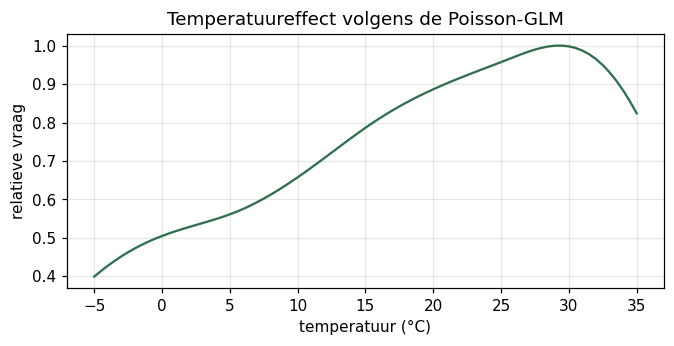

In [13]:
pre, reg = glm_model[1], glm_model[-1]
coefs = pd.Series(reg.coef_, index=pre.get_feature_names_out())
sd = pre.named_transformers_["num"].scale_[0]
print(f"Regen 1 mm/u: x{np.exp(coefs['num__log_precip'] * np.log1p(1) / sd):.2f} | 5 mm/u: x{np.exp(coefs['num__log_precip'] * np.log1p(5) / sd):.2f} | "
      f"feestdag: x{np.exp(coefs['cat__is_holiday_1'] - coefs['cat__is_holiday_0']):.2f}")
months = coefs.filter(like="cat__month_")
print("Maand t.o.v. januari:", (np.exp(months - months.iloc[0])).round(2).tolist())
temps = np.linspace(-5, 35, 81)
probe = X24.iloc[[0] * len(temps)].assign(temperature_c=temps, precipitation_mm=0.0, wind_kmh=10.0)
curve = glm_model.predict(probe)
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(temps, curve / curve.max(), color=GREEN)
ax.set(xlabel="temperatuur (°C)", ylabel="relatieve vraag", title="Temperatuureffect volgens de Poisson-GLM")
plt.show()

**Resultaat:** de interactie zone × uur × weekend verlaagt de fout van 37 naar 30 (CV). Op de testset: **MAE 33,2, R² 0,89**. Wat het model ons "gratis" leert:
- regen: **−30%** bij 1 mm/u, −60% bij 5 mm/u (in lijn met hypothese B1);
- feestdag: **−17%**;
- oktober heeft 1,7 keer de vraag van januari, **bij dezelfde temperatuur** (forenzen en studenten zijn terug);
- de vraag stijgt met de temperatuur tot een optimum rond **29 °C** en daalt daarboven.

**Verder?** **Nee, niet als voorspeller.** Het blijft duidelijk minder goed dan de bomen hieronder: het mist interacties die we niet zelf bouwden (bv. regen × weekend, uit A3 en de regencurve), en de `log1p`-vorm dwingt een steeds groter regeneffect af, terwijl de data een afvlakking boven 5 mm/u toont. We gebruiken het wel voor de **uitleg** van de effecten.

## C3. Random forest
**Waarom:** veel diepe bomen op bootstrap-steekproeven, gemiddeld (**bagging**). Vindt interacties zelf en is robuust.

In [14]:
rf_info = json.loads((cb.METRICS_2024 / "random_forest.json").read_text())
default_rf = RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=cb.SEED)
print("standaardinstellingen, CV-MAE:", cb.cv_scores(default_rf, X24, y24, g24)["cv_mae_mean"])
if RUN_SEARCHES:
    search = RandomizedSearchCV(RandomForestRegressor(n_estimators=150, n_jobs=-1, random_state=cb.SEED),
                                {"min_samples_leaf": randint(1, 8), "max_features": uniform(0.6, 0.4),
                                 "max_depth": [None, 25, 35], "max_samples": uniform(0.5, 0.5)},
                                n_iter=15, cv=GroupKFold(5), scoring="neg_mean_absolute_error", random_state=cb.SEED)
    rf_params = search.fit(X24, y24, groups=g24).best_params_
else:
    rf_params = rf_info["params"]
print("gekozen:", rf_params, "| beste uit de eerste, brede zoekronde had CV-MAE", rf_info["cv_mae_round1_best"])
rf = RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=cb.SEED, **rf_params)
cv = cb.cv_scores(rf, X24, y24, g24)
record("random_forest", cv, rf.fit(X24, y24).predict(X24t))

standaardinstellingen, CV-MAE: 28.1429
gekozen: {'max_depth': 25, 'max_features': 0.8099025726528951, 'max_samples': 0.7159725093210578, 'min_samples_leaf': 1} | beste uit de eerste, brede zoekronde had CV-MAE 30.9192


cv_mae              27.3988
mae                 30.3160
rmse                58.9400
r2                   0.8967
poisson_deviance    13.9710
dtype: float64

**Resultaat:** standaard CV-MAE 28,1; na tuning **27,4**; test **30,3**, R² 0,90.

**Een les uit het tunen:** de eerste zoekronde (grote bladeren tot 30 uren, 30–100% van de kenmerken per split) maakte het model **slechter** dan de standaard (30,9). De standaard random forest gebruikt álle kenmerken en bladeren van 1 uur, en precies dat gebied had de zoekruimte uitgesloten. Een tweede ronde rond de standaard vond wel een verbetering (kleinere bootstrap-steekproeven per boom: meer diverse bomen).

**Verder?** **Nee.** Beter dan de GLM, maar minder goed dan gradient boosting (hieronder), en 300 bomen tot diepte 25 maken een groot, traag model voor de server.

## C4. AutoML met PyCaret
**Waarom:** een onafhankelijke controle. Probeert AutoML iets wat wij over het hoofd zagen? We gaven PyCaret dezelfde split en dezelfde week-folds.

In [15]:
if RUN_SEARCHES:
    from pycaret.regression import compare_models, predict_model, pull, setup, tune_model
    train_df = X24.assign(trips=y24.to_numpy(), week=g24.to_numpy())
    setup(data=train_df, test_data=X24t.assign(trips=y24t.to_numpy(), week=0), target="trips", session_id=cb.SEED,
          categorical_features=["zone"], ignore_features=["week"], fold_strategy="groupkfold", fold_groups="week",
          fold=5, html=False, verbose=False, n_jobs=4)
    top3 = compare_models(sort="MAE", n_select=3, budget_time=25, verbose=False,
                          include=["lightgbm", "xgboost", "et", "rf", "gbr", "dt", "huber", "br", "ridge", "lasso", "en", "lr", "dummy"])
    leaderboard = pull()[["Model", "MAE", "RMSE", "R2"]]
    tree_grid = {"n_estimators": [100, 200, 300], "max_features": [0.6, 0.8, 1.0], "min_samples_leaf": [1, 2, 4], "max_depth": [None, 20, 30]}
    best = min((tune_model(m, n_iter=15, optimize="MAE", choose_better=True, verbose=False,
                           custom_grid=tree_grid if type(m).__name__ in ("ExtraTreesRegressor", "RandomForestRegressor") else None)
                for m in top3), key=lambda m: pull().loc["Mean", "MAE"])
    pyc_pred = predict_model(best, verbose=False)["prediction_label"].to_numpy()
else:
    pyc = json.loads((cb.METRICS_2024 / "pycaret.json").read_text())
    leaderboard = pd.DataFrame(pyc["leaderboard"])[["Model", "MAE", "RMSE", "R2"]]
    print("Getuned:", pyc["tuning"])
    pyc_pred = pd.read_parquet(cb.PRED_2024 / "pycaret.parquet")["pred"].to_numpy()
display(leaderboard)
record("pycaret", None, pyc_pred)

Getuned: [{'model': 'ExtraTreesRegressor', 'cv_mae_getuned': 26.6368}, {'model': 'RandomForestRegressor', 'cv_mae_getuned': 27.5106}, {'model': 'LGBMRegressor', 'cv_mae_getuned': 29.3975}]


,Model,MAE,RMSE,R2
0,Extra Trees Regressor,26.9570,48.6290,0.9317
1,Random Forest Regressor,28.1429,51.5001,0.9235
2,Light Gradient Boosting Machine,30.7167,51.2190,0.9257
3,Extreme Gradient Boosting,31.1993,52.8560,0.9201
4,Decision Tree Regressor,36.2355,66.2374,0.8746
5,Gradient Boosting Regressor,47.0773,78.1124,0.8288
6,Huber Regressor,93.4384,142.6795,0.4302
7,Lasso Regression,97.0771,138.5602,0.4620
8,Elastic Net,97.0930,138.7535,0.4604
9,Bayesian Ridge,97.2238,138.5170,0.4623


cv_mae                  NaN
mae                 30.5775
rmse                59.9382
r2                   0.8932
poisson_deviance    14.5678
dtype: float64

**Resultaat:** bomen-ensembles winnen ook hier (Extra Trees 27,0 → getuned 26,6 CV; test **30,6**). De lineaire modellen falen volledig (MAE ± 97): ze krijgen de ruwe kolommen, met het uur als één getal en zonder interacties. Ons eigen GLM met zone × uur × weekend haalde 33: het verschil is volledig **feature engineering**.

Twee valkuilen die we onderweg tegenkwamen:
- PyCaret draaide de folds parallel én gaf elk model `n_jobs=-1`: 22 processen probeerden elk alle kernen te gebruiken (*oversubscription*), en na een uur was het nog niet klaar. Opgelost met `n_jobs=4` en een tijdsbudget;
- de standaard-zoekruimte voor random forest/extra trees bevat `criterion="absolute_error"`, onwerkbaar traag op 160.000 rijen. Opgelost met een eigen zoekruimte;
- en PyCaret behandelde de zone stilzwijgend als **getal** ("No categorical columns found"), ondanks `categorical_features=["zone"]`.

**Verder?** **Nee.** AutoML vond geen beter model dan ons eigen gradient boosting-model. Het bevestigt wel de keuze voor boom-ensembles.

## C5. Gradient boosting (HistGradientBoosting, Poisson)
**Waarom:** bomen **na elkaar**, elke boom leert de fouten van de vorige (**boosting**); op tabeldata meestal het sterkst. De histogram-variant is snel op honderdduizenden rijen, `loss="poisson"` past bij tellingen, de zone is een echte categorie, en het draait met alleen scikit-learn (niets extra op de server).

In [16]:
quick = hgb(F24)
record("quick_hgb", cb.cv_scores(quick, X24, y24, g24), quick.fit(X24, y24).predict(X24t))
params24 = json.loads((cb.MODEL_2024 / "best_params.json").read_text())["params"]
if RUN_SEARCHES:
    search = RandomizedSearchCV(hgb(F24), {"learning_rate": loguniform(0.02, 0.3), "max_iter": randint(200, 1200),
                                           "max_leaf_nodes": randint(15, 127), "min_samples_leaf": randint(10, 200),
                                           "l2_regularization": loguniform(1e-3, 10)},
                                n_iter=25, cv=GroupKFold(5), scoring="neg_mean_absolute_error", random_state=cb.SEED)
    params24 = {k: (round(float(v), 6) if isinstance(v, float) else int(v))
                for k, v in search.fit(X24, y24, groups=g24).best_params_.items()}
print("hyperparameters:", params24)
hgb24 = hgb(F24, **params24)
cv_hgb24 = cb.cv_scores(hgb24, X24, y24, g24)
record("hist_gradient_boosting", cv_hgb24, hgb24.fit(X24, y24).predict(X24t))

hyperparameters: {'l2_regularization': 0.015314, 'learning_rate': 0.03129, 'max_iter': 1056, 'max_leaf_nodes': 85, 'min_samples_leaf': 18}


cv_mae              24.8879
mae                 29.0454
rmse                56.3468
r2                   0.9056
poisson_deviance    12.5921
dtype: float64

**Resultaat:** ongetuned al CV 27,6 / test 30,9; getuned (25 combinaties × 5 folds) **CV 24,9 / test 29,0, R² 0,906**. De beste combinaties delen een kleine learning rate (0,02–0,07) en grote bomen (75+ bladeren).

**Verder?** **Ja**: het beste model (zie C7).

## C6. Experiment: de recente vraag als kenmerk (lags)
**Waarom:** tijdreeksen hebben **autocorrelatie** (AWS-hoofdstuk 4): het aantal ritten nu lijkt op dat van gisteren en vorige week op hetzelfde uur. Hoeveel zou een model winnen met `lag_24h` en `lag_168h`?

In [17]:
lagged = t24.sort_values(["zone", "time"]).copy()
for h in [24, 168]:
    lagged[f"lag_{h}h"] = lagged.groupby("zone")["trips"].shift(h)
lagged = lagged.loc[t24.index]
X_lag = pd.concat([cb.make_features(lagged, F24), lagged[["lag_24h", "lag_168h"]]], axis=1)
is_test24 = (t24["split"] == "test").to_numpy()
lag_model = hgb(F24, **params24)
cv_lag = cb.cv_scores(lag_model, X_lag[~is_test24], y24, g24)
lag_pred = lag_model.fit(X_lag[~is_test24], y24).predict(X_lag[is_test24])
pd.DataFrame({"zonder lags": {"cv_mae": cv_hgb24["cv_mae_mean"], **cb.evaluate(y24t, preds24["hist_gradient_boosting"]["pred"])},
              "met lags": {"cv_mae": cv_lag["cv_mae_mean"], **cb.evaluate(y24t, lag_pred)}}).round(3)

,zonder lags,met lags
cv_mae,24.888,27.470
mae,29.045,26.897
rmse,56.347,51.048
r2,0.906,0.922
poisson_deviance,12.592,10.357


**Resultaat:** op de testset beter (26,9 tegenover 29,0), maar in de cross-validatie **slechter** (27,5 tegenover 24,9) en in geen enkele fold beter. Een inconsistent beeld: waarschijnlijk stuurt een lag van een uitzonderlijke dag (feestdag, storm) het model een dag of week later de verkeerde kant op.

**Verder?** **Nee**, om twee redenen: de winst is niet betrouwbaar (een **misleidende testverbetering**: beter op één testset, slechter in elke fold), en het model zou niet bruikbaar zijn: wie op de webpagina een voorspelling voor volgende week vraagt, kent de vertrekken van gisteren niet. Daarvoor zou de API een live koppeling met Citi Bike nodig hebben.

## C7. Vergelijking en keuze

In [18]:
order24 = ["baseline", "poisson_glm", "random_forest", "pycaret", "quick_hgb", "hist_gradient_boosting"]
overview24 = pd.DataFrame(results24).T.loc[order24, ["cv_mae", "mae", "rmse", "r2", "poisson_deviance"]].astype(float).round(3)
display(overview24)
pd.DataFrame({name: paired_bootstrap(preds24["hist_gradient_boosting"], preds24[name])
              for name in order24[:-1]}).T

,cv_mae,mae,rmse,r2,poisson_deviance
baseline,59.186,59.275,96.441,0.724,34.188
poisson_glm,30.454,33.189,60.397,0.892,14.589
random_forest,27.399,30.316,58.940,0.897,13.971
pycaret,NaN,30.578,59.938,0.893,14.568
quick_hgb,27.566,30.883,57.150,0.903,13.312
hist_gradient_boosting,24.888,29.045,56.347,0.906,12.592


,MAE-winst,95%-BI,P(beter)
baseline,30.16,"[24.73, 35.69]",1.0
poisson_glm,4.14,"[2.4, 5.84]",1.0
random_forest,1.28,"[0.18, 2.52]",0.989
pycaret,1.54,"[0.27, 2.95]",0.995
quick_hgb,1.84,"[1.0, 2.64]",1.0


**Resultaat:** gradient boosting is het beste op elke maatstaf. De bootstrap per dag (2.000 keer hele testdagen hertrekken) toont dat de voorsprong echt is: tegenover de baseline +30 vertrekken per uur, het GLM +4,1, het ongetunede model +1,8, en tegenover random forest (+1,3) en PyCaret (+1,5) klein maar met een 95%-interval boven 0.

**Keuze:** **HistGradientBoosting met Poisson-verlies.** Beste fout, klein en snel model (± 5 MB), alleen scikit-learn nodig op de server.

### Waar vergist het 2024-model zich? (de aanleiding voor deel D)

In [19]:
r = preds24["hist_gradient_boosting"]
day_err = r.groupby(r["time"].dt.normalize())[["trips", "pred"]].sum()
day_err["fout %"] = ((day_err["pred"] / day_err["trips"] - 1) * 100).round(0)
day_err.reindex(day_err["fout %"].abs().sort_values(ascending=False).index).head(5)

,trips,pred,fout %
time,,,
2024-12-25,21562,67519.740197,213.0
2024-11-28,27089,71831.252950,165.0
2024-12-28,26708,66121.485329,148.0
2024-09-29,71242,140897.897264,98.0
2024-11-29,59764,114781.762840,92.0


De grootste fouten zitten op **Kerstmis** (3 keer te veel voorspeld) en **Thanksgiving**. Die vallen in de testweken, en in het ene trainingsjaar heeft het model er geen enkel voorbeeld van gezien. Met **meer jaren** zou het er een tiental van elk kennen. Dat is de reden voor deel D.

---
# Deel D – Het definitieve model op alle data (2013–2026)
## D0. Wat verandert er?
- **Data:** 2,8 miljoen zone-uren, 13 jaar (zie `01_cleaning`).
- **Kenmerken:** die van 2024, plus `year` (trend), `active_stations` (aanbod in de zone, `01_cleaning` §11) en `snow_depth_cm` (sneeuw op de grond; toegevoegd na de foutenanalyse, zie D5).
- **Testset:** de laatste 12 maanden (oktober 2025 – september 2026): zo meten we zoals het model gebruikt wordt.
- **Validatie: backtesting** (AWS-hoofdstuk 4). Drie folds: trainen op alle jaren vóór een validatiejaar, valideren op dat jaar. De `GroupKFold` op weken uit 2024 zou het model voor 2019 laten leren van 2018 én 2020; met een sterke trend is dat te optimistisch.

In [20]:
X, y, _, Xt, yt = cb.train_test(table)
train_time = table.loc[table["split"] == "train", "time"].reset_index(drop=True)
folds = cb.backtest_folds(train_time)
for i, (tr, va) in enumerate(folds):
    print(f"fold {i}: train {train_time.iloc[tr].min():%Y-%m}–{train_time.iloc[tr].max():%Y-%m} -> "
          f"valideer {train_time.iloc[va].min():%Y-%m}–{train_time.iloc[va].max():%Y-%m}")
results, preds = {}, {}


def record_all(name, cv, pred):
    results[name] = {"backtest_mae": cv["cv_mae_mean"] if cv else None, **cb.evaluate(yt, pred)}
    preds[name] = test_frame(table, yt, pred)
    return pd.Series(results[name])

fold 0: train 2013-06–2022-09 -> valideer 2022-10–2023-09
fold 1: train 2013-06–2023-09 -> valideer 2023-10–2024-09
fold 2: train 2013-06–2024-09 -> valideer 2024-10–2025-09


## D1. Baseline op alle data

In [21]:
rows = {}
for name, kwargs in [("globaal gemiddelde", {"keys": ()}),
                     ("zone x uur x weekend, alle jaren", {"keys": ("zone", "hour", "is_weekend")}),
                     ("zone x uur x weekend, laatste 12 maanden", {"keys": ("zone", "hour", "is_weekend"), "recent_months": 12})]:
    rows[name] = cb.cv_scores(cb.GroupMeanRegressor(**kwargs), X, y, cv=folds)["cv_mae_mean"]
display(pd.Series(rows, name="backtest-MAE").round(1).to_frame())
base_all = cb.GroupMeanRegressor(keys=("zone", "hour", "is_weekend"), recent_months=12)
record_all("baseline", cb.cv_scores(base_all, X, y, cv=folds), base_all.fit(X, y).predict(Xt))

,backtest-MAE
globaal gemiddelde,120.0
"zone x uur x weekend, alle jaren",82.1
"zone x uur x weekend, laatste 12 maanden",57.6


backtest_mae         57.6031
mae                  70.9640
rmse                115.4286
r2                    0.6802
poisson_deviance     47.6182
dtype: float64

**Resultaat:** het gemiddelde over **alle jaren** (82) is veel slechter dan over **de laatste 12 maanden** (58): een gemiddelde over 13 jaar onderschat de vraag van vandaag (het netwerk is 7 keer groter). Een eerste aanwijzing dat "meer data" niet vanzelf beter is; het model moet de groei kunnen volgen. Op de testset haalt de baseline MAE 71,0 (R² 0,68).

## D2. Gradient boosting: standaard, 2024-instellingen, opnieuw getuned

In [22]:
quick_all = hgb()
record_all("quick_hgb", cb.cv_scores(quick_all, X, y, cv=folds), quick_all.fit(X, y).predict(Xt))
cv_2024params = cb.cv_scores(hgb(**params24), X, y, cv=folds)
params = json.loads((cb.MODEL_DIR / "best_params.json").read_text())["params"]
if RUN_SEARCHES:
    search = RandomizedSearchCV(hgb(), {"learning_rate": loguniform(0.02, 0.15), "max_iter": randint(500, 2000),
                                        "max_leaf_nodes": randint(63, 255), "min_samples_leaf": randint(20, 400),
                                        "l2_regularization": loguniform(1e-3, 10)},
                                n_iter=10, cv=folds, scoring="neg_mean_absolute_error", random_state=cb.SEED)
    params = {k: (round(float(v), 6) if isinstance(v, float) else int(v)) for k, v in search.fit(X, y).best_params_.items()}
final_model = hgb(**params)
cv_final = cb.cv_scores(final_model, X, y, cv=folds)
record_all("hist_gradient_boosting", cv_final, final_model.fit(X, y).predict(Xt))
pd.DataFrame({"standaard": results["quick_hgb"],
              "2024-instellingen (backtest)": {"backtest_mae": cv_2024params["cv_mae_mean"]},
              "opnieuw getuned": results["hist_gradient_boosting"]}).T.round(3)

,backtest_mae,mae,rmse,r2,poisson_deviance
standaard,36.366,36.054,63.832,0.902,14.912
2024-instellingen (backtest),31.993,NaN,NaN,NaN,NaN
opnieuw getuned,31.786,28.941,53.634,0.931,10.625


**Resultaat:**
- de **standaardinstellingen** volstaan niet meer (backtest 36,4): ze stoppen na 100 bomen, te weinig voor 2,5 miljoen rijen;
- de **instellingen uit 2024** halen al backtest 32,0;
- **opnieuw getuned** (10 combinaties × 3 backtest-folds): **31,8**, beter in alle drie de folds, maar maar een fractie. De beste combinaties gebruiken dezelfde kleine learning rate als in 2024, maar veel **grotere bladeren** (± 335 uren in plaats van 18): met 15 keer meer data kan elk blad op meer uren steunen.
- Op de testset: **MAE 28,9, R² 0,931**.

**Verder?** Ja, dit is het definitieve model. Hertunen bracht weinig op; de grote winst zit in de data en de kenmerken (D3–D5).

## D3. Helpt meer data echt? (leercurve over jaren)
Hetzelfde model, getraind op steeds meer jaren vóór de testperiode, telkens gemeten op dezelfde testset.

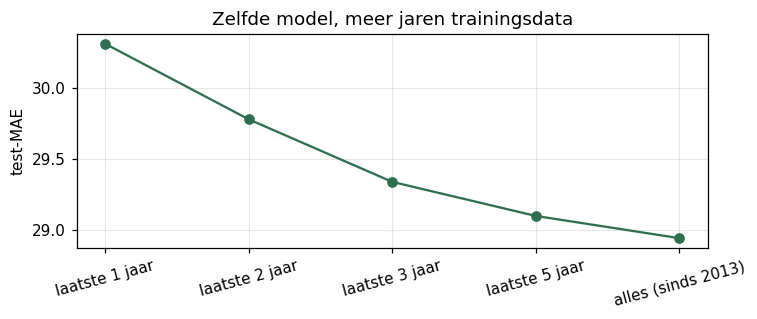

,zone-uren,mae,rmse,r2,poisson_deviance
laatste 1 jaar,262800.0,30.310,55.983,0.925,12.523
laatste 2 jaar,526320.0,29.778,54.782,0.928,11.948
laatste 3 jaar,781824.0,29.337,53.928,0.930,11.562
laatste 5 jaar,1278408.0,29.098,53.707,0.931,11.120
alles (sinds 2013),2556912.0,28.941,53.634,0.931,10.625


In [23]:
test_start = table.loc[table["split"] == "test", "time"].min()
volume = {}
for years in [1, 2, 3, 5, None]:
    since = test_start - pd.DateOffset(years=years) if years else train_time.min()
    keep = (train_time >= since).to_numpy()
    m = hgb(**params).fit(X[keep], y[keep])
    p = m.predict(Xt)
    label = f"laatste {years} jaar" if years else "alles (sinds 2013)"
    volume[label] = {"zone-uren": int(keep.sum()), **cb.evaluate(yt, p)}
    if years == 1:
        preds["hgb_one_year"] = test_frame(table, yt, p)
        results["hgb_one_year"] = {"backtest_mae": None, **cb.evaluate(yt, p)}
volume = pd.DataFrame(volume).T
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(range(len(volume)), volume["mae"], "o-", color=GREEN)
ax.set(xticks=range(len(volume)), xticklabels=volume.index, ylabel="test-MAE", title="Zelfde model, meer jaren trainingsdata")
plt.setp(ax.get_xticklabels(), rotation=15); plt.tight_layout(); plt.show()
volume.round(3)

**Resultaat:** **ja**, bij elke stap: 30,3 (1 jaar) → 29,8 → 29,3 → 29,1 → **28,9 (alles)**. De winst neemt af: de oudste jaren (een veel kleiner netwerk zonder e-bikes) voegen nog maar weinig toe, maar schaden ook niet, dankzij `year` en `active_stations`.

## D4. Helpen de nieuwe kenmerken? (ablatie)
We laten de nieuwe kenmerken één voor één weg en meten opnieuw, op de backtest én op de testset.

In [24]:
ablation = {}
for name, drop in [("alle kenmerken", []), ("zonder year", ["year"]), ("zonder active_stations", ["active_stations"]),
                   ("zonder snow_depth_cm", ["snow_depth_cm"]),
                   ("zonder alle drie (= kenmerken uit 2024)", ["year", "active_stations", "snow_depth_cm"])]:
    feats = [f for f in cb.FEATURES if f not in drop]
    backtest = cb.cv_scores(hgb(feats, **params), X[feats], y, cv=folds)
    m = hgb(feats, **params).fit(X[feats], y)
    p = m.predict(Xt[feats])
    ablation[name] = {"backtest_mae": backtest["cv_mae_mean"], **{f"fold {i}": v for i, v in enumerate(backtest["cv_mae"])},
                      **cb.evaluate(yt, p)}
    if name == "zonder snow_depth_cm":
        preds["zonder_sneeuw"] = test_frame(table, yt, p)
pd.DataFrame(ablation).T.round(3)

,backtest_mae,fold 0,fold 1,fold 2,mae,rmse,r2,poisson_deviance
alle kenmerken,31.786,27.367,38.497,29.494,28.941,53.634,0.931,10.625
zonder year,37.720,30.238,42.372,40.549,35.084,62.946,0.905,14.297
zonder active_stations,32.247,28.059,39.162,29.519,29.212,53.785,0.931,10.848
zonder snow_depth_cm,31.690,27.478,37.885,29.706,30.141,55.079,0.927,11.744
zonder alle drie (= kenmerken uit 2024),74.548,56.278,77.604,89.761,78.962,129.568,0.597,69.017


**Resultaat:**
- **`year` is onmisbaar** (zonder: test 35,1, backtest 37,7). Zonder alle drie de nieuwe kenmerken is het model **onbruikbaar** op alle data (MAE 79, R² 0,60): het middelt dan 13 jaar groei uit, net als de baseline over alle jaren.
- **`active_stations`** voegt naast `year` weinig maar consistent toe (beter in elke fold).
- **`snow_depth_cm`** helpt op de testset sterk (30,1 → 28,9) maar **niet in de backtest** (31,7 zonder, 31,8 met). Zie D5.

## D5. Een iteratie: sneeuw op de grond
**Aanleiding:** in een eerste versie van de foutenanalyse (deel E, toen nog zonder `snow_depth_cm`) zaten de grootste fouten op **droge dagen ná een sneeuwstorm**: op 26 januari 2026 voorspelde het model 9 keer te veel. Het kende alleen de neerslag van het uur zelf en wist niet dat de straten nog wit lagen.

**Aanpassing:** de sneeuwhoogte (cm sneeuw op de grond, Open-Meteo) als kenmerk. Effect op de dagen na de storm van eind januari 2026:

In [25]:
compare = pd.DataFrame({k: preds[k].groupby(preds[k]["time"].dt.normalize())[["trips", "pred"]].sum()["pred"]
                        for k in ["zonder_sneeuw", "hist_gradient_boosting"]})
compare["werkelijk"] = preds["hist_gradient_boosting"].groupby(preds["hist_gradient_boosting"]["time"].dt.normalize())["trips"].sum()
snow_day = table.groupby(table["time"].dt.normalize())["snow_depth_cm"].max()
window = compare.loc["2026-01-24":"2026-02-01"].join(snow_day.rename("sneeuw_cm"))
window.assign(**{f"fout % {k}": ((window[k] / window["werkelijk"] - 1) * 100).round(0)
                 for k in ["zonder_sneeuw", "hist_gradient_boosting"]}).round(0)

,zonder_sneeuw,hist_gradient_boosting,werkelijk,sneeuw_cm,fout % zonder_sneeuw,fout % hist_gradient_boosting
time,,,,,,
2026-01-24,36483.0,39698.0,41957,1.0,-13.0,-5.0
2026-01-25,11602.0,10920.0,3051,29.0,280.0,258.0
2026-01-26,58836.0,40737.0,6058,26.0,871.0,572.0
2026-01-27,50745.0,29920.0,16123,21.0,215.0,86.0
2026-01-28,54552.0,35547.0,20656,19.0,164.0,72.0
2026-01-29,51472.0,35570.0,22508,19.0,129.0,58.0
2026-01-30,44181.0,30787.0,20446,19.0,116.0,51.0
2026-01-31,38174.0,26968.0,18436,19.0,107.0,46.0
2026-02-01,28120.0,21828.0,15901,18.0,77.0,37.0


**Resultaat:** de fout op de dagen met sneeuw op straat halveert ruwweg (bv. 27 januari: van +215% naar +86%), en de test-MAE daalt van 30,1 naar 28,9.

**Waarom dan niet zichtbaar in de backtest?** De validatiejaren (2022–2025) hadden zachte winters met weinig sneeuw op de grond; de testwinter was de koudste en sneeuwrijkste in jaren. Het kenmerk helpt alleen als er sneeuw ligt.

**Verder?** **Ja, met een kanttekening.** Het mechanisme is logisch en het effect zit precies op de juiste dagen, maar het is gemeten op één sneeuwrijke winter. Dat onderscheidt het van de lags in C6: die waren in **elke** fold slechter, de sneeuwhoogte is in de backtest neutraal (beter in 2 van de 3 folds).

---
# Deel E – Foutenanalyse van het definitieve model

In [26]:
best, one = preds["hist_gradient_boosting"], preds["hgb_one_year"]
order = ["baseline", "quick_hgb", "hgb_one_year", "hist_gradient_boosting"]
overview = pd.DataFrame(results).T.loc[order].astype(float)
overview["relatieve MAE"] = overview["mae"] / yt.mean()
display(overview.round(3))
pd.DataFrame({name: paired_bootstrap(best, preds[name]) for name in order[:-1]}).T

,backtest_mae,mae,rmse,r2,poisson_deviance,relatieve MAE
baseline,57.603,70.964,115.429,0.680,47.618,0.410
quick_hgb,36.366,36.054,63.832,0.902,14.912,0.208
hgb_one_year,NaN,30.310,55.983,0.925,12.523,0.175
hist_gradient_boosting,31.786,28.941,53.634,0.931,10.625,0.167


,MAE-winst,95%-BI,P(beter)
baseline,42.04,"[38.52, 45.71]",1.0
quick_hgb,7.12,"[6.56, 7.67]",1.0
hgb_one_year,1.37,"[0.66, 2.07]",1.0


**Resultaat:** het definitieve model zit gemiddeld **28,9 vertrekken per uur** naast, bij een gemiddelde vraag van 173: **16,7%**. In de 2024-studie was dat 17,8% (andere testset, voorzichtig vergelijken). Tegenover hetzelfde model op één jaar data wint het 1,4 vertrekken per uur (95%-BI 0,7 tot 2,1): klein, maar echt.

## E1. Per maand, en waar meer data het verschil maakt

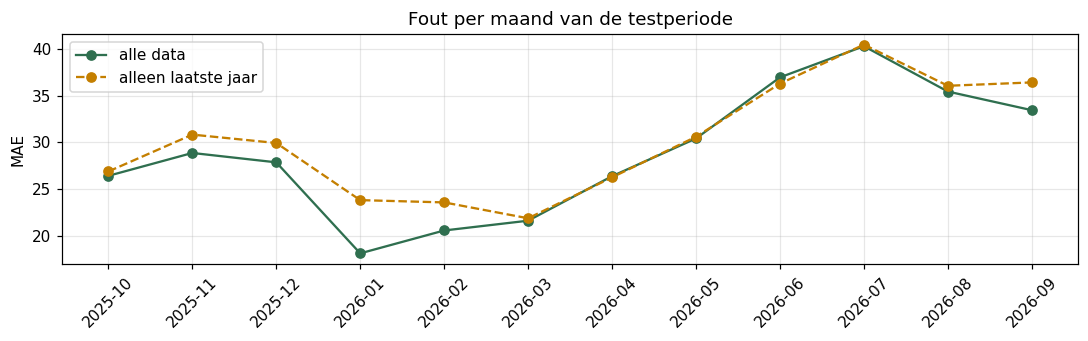

time,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09
vraag,211.9,158.1,93.7,81.3,62.7,131.9,178.6,210.2,249.1,223.6,234.9,230.5
mae,26.4,28.9,27.9,18.1,20.6,21.6,26.4,30.4,37.0,40.3,35.4,33.5
mae_1_jaar,26.9,30.8,29.9,23.8,23.6,21.9,26.3,30.6,36.3,40.5,36.1,36.4


In [27]:
res = best.merge(table[["zone", "time", "precipitation_mm", "snow_depth_cm"]], on=["zone", "time"])
res["abs_error"] = (res["pred"] - res["trips"]).abs()
res["abs_error_1j"] = (one["pred"].to_numpy() - res["trips"]).abs()
res["pred_1j"] = one["pred"].to_numpy()
monthly = res.groupby(res["time"].dt.to_period("M")).agg(vraag=("trips", "mean"), mae=("abs_error", "mean"), mae_1_jaar=("abs_error_1j", "mean"))
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(monthly.index.astype(str), monthly["mae"], "o-", color=GREEN, label="alle data")
ax.plot(monthly.index.astype(str), monthly["mae_1_jaar"], "o--", color=ORANGE, label="alleen laatste jaar")
ax.set(ylabel="MAE", title="Fout per maand van de testperiode"); ax.legend(); plt.setp(ax.get_xticklabels(), rotation=45)
plt.tight_layout(); plt.show()
monthly.round(1).T

**Resultaat:** in bijna elke maand beter dan het model op één jaar, en het meest in **januari en februari 2026**, de sneeuwmaanden: 13 jaar bevat meerdere sneeuwwinters, één jaar bijna geen. In absolute fout is de zomer het moeilijkst (daar zijn ook de meeste ritten).

## E2. Feestdagen (de zwakke plek uit 2024)

In [28]:
daily = res.groupby(res["time"].dt.normalize()).agg(trips=("trips", "sum"), pred=("pred", "sum"), pred_1j=("pred_1j", "sum"),
                                                    sneeuw_cm=("snow_depth_cm", "max"))
daily["fout %"] = ((daily["pred"] / daily["trips"] - 1) * 100).round(0)
daily["fout % (1 jaar)"] = ((daily["pred_1j"] / daily["trips"] - 1) * 100).round(0)
holidays = cb.us_holidays(daily.index.min(), daily.index.max())
special = holidays.union(pd.DatetimeIndex([h + pd.Timedelta(days=1) for h in holidays if h.month == 11 and h.day >= 22]))
special = special.union(pd.date_range(f"{daily.index.min().year}-12-24", f"{daily.index.min().year + 1}-01-01"))
daily.loc[daily.index.isin(special), ["trips", "pred", "fout %", "fout % (1 jaar)"]]

,trips,pred,fout %,fout % (1 jaar)
time,,,,
2025-10-13,61079,86293.454867,41.0,66.0
2025-11-11,96690,46864.929569,-52.0,-63.0
2025-11-27,45245,47399.020453,5.0,-22.0
2025-11-28,53762,90148.596305,68.0,40.0
2025-12-24,50826,103060.674219,103.0,90.0
2025-12-25,25529,32230.501679,26.0,38.0
2025-12-26,30140,66761.315820,122.0,145.0
2025-12-27,12864,38265.557088,197.0,143.0
2025-12-28,23486,31136.240132,33.0,28.0


**Resultaat:** de feestdagen zelf gaan nu goed: **Thanksgiving +5%** (2024-studie: +165%), **Kerstmis +26%** (+213%), Nieuwjaar −4%, Memorial Day +11%, Labor Day −7%. Wat nog misgaat: de dagen **rond** de feestdagen die zelf geen feestdag zijn (de dag na Thanksgiving, kerstavond, de week tot Nieuwjaar: +33% tot +197%), en **Veterans Day** (−52%: veel New Yorkers werken dan gewoon, maar het model behandelt alle feestdagen hetzelfde).

**Niet gedaan, wel een volgende stap:** een kenmerk voor vakantieperiodes en aparte kenmerken per soort feestdag.

## E3. De grootste dagfouten, neerslag en zones

In [29]:
display(daily.reindex(daily["fout %"].abs().sort_values(ascending=False).index).head(8)[["trips", "pred", "fout %", "sneeuw_cm"]])
res["regen"] = pd.cut(res["precipitation_mm"], [-0.01, 0, 0.5, 2, 100], labels=["droog", "≤0,5 mm", "0,5–2 mm", ">2 mm"])
display(res.groupby("regen", observed=True).agg(uren=("trips", "size"), werkelijk=("trips", "mean"), voorspeld=("pred", "mean"),
                                                mae=("abs_error", "mean"), mae_1_jaar=("abs_error_1j", "mean")).round(1))
zones = pd.DataFrame(json.loads((cb.DATA_DIR / "zones.json").read_text(encoding="utf-8"))).set_index("zone")
by_zone = (res.assign(err=res["pred"] - res["trips"]).groupby("zone")
             .agg(vraag=("trips", "mean"), mae=("abs_error", "mean"), bias=("err", "mean"))
             .assign(relatief=lambda d: d["mae"] / d["vraag"]).join(zones[["name", "active_stations"]]))
by_zone.sort_values("relatief", ascending=False).head(5).round(2)

,trips,pred,fout %,sneeuw_cm
time,,,,
2026-01-26,6058,40737.238527,572.0,26.0
2026-01-25,3051,10919.596967,258.0,29.0
2025-12-27,12864,38265.557088,197.0,10.0
2026-02-24,13119,32950.541485,151.0,51.0
2025-12-26,30140,66761.315820,122.0,5.0
2025-12-24,50826,103060.674219,103.0,1.0
2026-01-27,16123,29920.216429,86.0,21.0
2026-02-22,19029,34008.704244,79.0,8.0


,uren,werkelijk,voorspeld,mae,mae_1_jaar
regen,,,,,
droog,221160,177.3,174.1,26.6,27.5
"≤0,5 mm",23130,182.7,179.0,42.4,44.1
"0,5–2 mm",12180,121.6,124.5,40.4,46.5
>2 mm,5610,76.6,102.1,42.6,47.2


,vraag,mae,bias,relatief,name,active_stations
zone,,,,,,
28,49.74,13.19,-7.22,0.27,rond 81 St & 34 Ave,174
29,31.71,7.67,0.29,0.24,rond 36 St & 4 Ave,101
27,58.84,13.95,-7.97,0.24,rond E Fordham Rd & Webster Ave,190
17,134.68,26.89,-11.37,0.20,rond Franklin St & Dupont St,37
24,72.13,13.99,-3.70,0.19,rond Parkside Ave & Ocean Ave,98


**Resultaat:**
- de grootste dagfouten blijven **vlak na zware sneeuw** (25–27 januari, 24 februari 2026, tot 51 cm) en in de **kerstvakantie**. Op de dag zelf of vlak na een storm weet het model niet of de straten al geruimd zijn of het systeem deels dicht is;
- bij **zware regen** (> 2 mm/u) overschat het model nog (102 voorspeld, 77 werkelijk), al doet het beter dan het model op één jaar;
- de grootste relatieve fout zit in de snelst **groeiende** zones (27: Fordham, de Bronx; 28: Jackson Heights, Queens). Daar **onderschat** het model de vraag: nieuwe stations worden steeds beter gebruikt, en dat volgt het met vertraging.

## E4. Welke kenmerken gebruikt het model? (permutation importance)
We husselen één kolom van (een steekproef van 200.000 uren uit) de testset en meten hoeveel de MAE stijgt.

In [30]:
sample = Xt.sample(200_000, random_state=cb.SEED)
imp = permutation_importance(final_model, sample, yt.loc[sample.index], scoring="neg_mean_absolute_error",
                             n_repeats=3, random_state=cb.SEED)
pd.Series(imp.importances_mean, index=cb.FEATURES).sort_values(ascending=False).round(2).rename("MAE-stijging")

hour                101.92
zone                 93.84
temperature_c        38.60
weekday              20.38
precipitation_mm      8.24
month                 7.07
snow_depth_cm         4.78
active_stations       4.30
is_holiday            1.82
wind_kmh              0.61
is_weekend            0.41
year                  0.00
Name: MAE-stijging, dtype: float64

**Resultaat:** uur en zone blijven veruit het belangrijkst, dan temperatuur en weekdag; sneeuwhoogte en actieve stations dragen duidelijk bij. Opvallend: **`year` scoort 0**, terwijl het model zonder `year` veel slechter is (D4). Geen tegenspraak: permutation importance husselt **binnen de testset**, en daarin is het jaar bijna overal 2025 of 2026. `year` is nodig om bij het **trainen** de jaren uit elkaar te houden, niet om binnen één testjaar te onderscheiden.

---
# Deel F – Deployment
## F1. Van notebook naar API
```
models/best_params.json  ->  train.py  ->  deploy/citi_bike_demand/model.pkl  ->  merge naar main
  -> GitHub Actions (deploy-api.yml): testen, kopiëren naar de Oracle VM, herstarten, rollback als de API niet start
  -> api_smoke_test.yml (na elke deploy en dagelijks)
```
- `train.py` meet het model eerst eerlijk (trainen op het verleden, testen op de laatste 12 maanden), weigert het als het meer dan 2% slechter is dan het model dat er staat, en hertraint het daarna op **alle** uren (ook de laatste 12 maanden: de meest recente data is de nuttigste voor de toekomst).
- De **API** (FastAPI, `/citi_bike_demand`) berekent dezelfde kenmerken als de training (`make_features`, gecontroleerd door `test_features.py`), met het **huidige** aantal actieve stations per zone.
- De **webpagina** (`citi_bike_demand.html`) haalt het weer (ook de sneeuwhoogte) automatisch op bij Open-Meteo en toont de verwachte vertrekken per uur voor een gekozen zone en dag, met scenario's (droog / regen).

In [31]:
out = subprocess.run([sys.executable, str(KOBE / "train.py")], capture_output=True, text=True, cwd=KOBE)
print(out.stdout[-1200:], out.stderr[-600:])

Data: 2,818,992 zone-uren (2,556,912 train / 262,080 test: 2025-10-01 t/m 2026-09-30), 30 zones
Hold-out: {'mae': 28.9411, 'rmse': 53.6342, 'r2': 0.9309, 'poisson_deviance': 10.6251}
Huidig model: MAE 28.9411; nieuw: 28.9411 (grens 29.5199)
Bundle geschreven naar C:\Users\kobev\Documents\semester 1\3APPAI - Deep Learning\CloudAI-Challenge\deploy\citi_bike_demand\model.pkl (7.1 MB)
 


---
# Deel G – Conclusie
## Wat we probeerden, wat het gaf, en waarom we wel of niet verder gingen
| Poging | Waarom | Resultaat | Verder? |
|---|---|---|---|
| Baseline (gemiddelde per zone × uur × weekend) | weten wat "goed" is | 2024: MAE 59; alle data: 71 | als lat |
| Poisson-GLM met interactie | uitlegbare effecten | MAE 33,2; regen −30%/mm, feestdag −17% | nee als voorspeller (mist interacties), wel voor uitleg |
| Random forest | bagging, interacties | MAE 30,3; eerste zoekronde maakte het slechter | nee: minder goed dan boosting, groot model |
| PyCaret (AutoML) | onafhankelijke controle | Extra Trees 30,6; lineaire modellen 97 | nee: geen beter model |
| **Gradient boosting (Poisson)** | **boosting, Poisson, klein en snel** | **2024: MAE 29,0** | **ja** |
| Lags (recente vraag) | autocorrelatie | test beter, CV slechter in elke fold | nee: misleidend, en niet bruikbaar zonder live data |
| **Alle data (2013–2026)** | zeldzame dagen leren | **MAE 28,9, R² 0,931**; feestdagen goed | **ja (gedeployd)** |
| `year`, `active_stations` | groei van het netwerk | zonder: onbruikbaar (MAE 79) | ja |
| `snow_depth_cm` | grootste fouten na sneeuwstormen | test 30,1 → 28,9; backtest neutraal | ja, met kanttekening |
| Hertunen op alle data | meer data, andere optimale instellingen | backtest 32,0 → 31,8 | ja (kleine winst) |

## Wat het model kan, en wat niet
- Het voorspelt de vraag per zone per uur met een gemiddelde fout van ± 17%, en vangt het dagritme, het seizoen, het weer, feestdagen en de groei van het netwerk.
- Het vergist zich vooral in de **kerstvakantie**, **vlak na zware sneeuw**, bij **zware buien**, en in **snelgroeiende zones**.
- **Beperkingen:** de data bevat gerealiseerde ritten, geen echte vraag (een leeg station telt als 0); het weer komt van één punt in de stad; evenementen en stationsstoringen ontbreken.
- **Volgende stappen:** kenmerken voor vakantieperiodes en per soort feestdag, weer per zone, en (met een live koppeling) de beschikbaarheid van fietsen.